# Yeni Graph Policy — Tasarım Taslağı (Adım 1–3)

Bu notebook, **sıfırdan kuracağımız yeni neural network** için şu ana kadar
kilitlettiğimiz kararları kodla birlikte gösterir.

Henüz **policy head ve eğitim yok** — burada:

**obs → ham node feature (34) + graph metrikleri (8) → edge (mesafe) → FC graph → GNN**

## Kilitlemiş kararlar

| # | Karar |
|---|--------|
| 1 | **Observation aynı** — `obs_builder.build_observation()` değişmez |
| 2 | **Her gezegen = graph node** — padding slotları graph'a girmez |
| 3 | **Node feature = `planet_feats` (34) + graph metrikleri (8)** — concat, embed yok |
| 4 | **Graph = fully connected directed** — her `(i→j)`, `i≠j` |
| 5 | **Edge feature = mesafe** — `edge_bias[i,j,0]` (dist/100) |
| 6 | **GNN doğrudan ham feature alır** — `NodeEmbed` / `EdgeEmbed` **kullanılmaz** |

## Pipeline

    env obs
       ↓
    build_observation()          ← DEĞİŞMEZ
       ↓
    planet_feats (n, 34)
    graph_node_metrics (n, 8)  ← ETA-kernel ile türetilir
       ↓ concat
    X_gnn (n, 42)
    edge_attr (E, 1)           ← mesafe
    edge_index (2, n·(n-1))
       ↓
    GINEConv stack (embed yok)
       ↓
    (TODO) policy head (src, tgt, ship)

## 1. Import'lar ve sabitler

In [23]:
import logging
logging.disable(logging.CRITICAL)

import os, sys, copy
_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if _root not in sys.path:
    sys.path.insert(0, _root)

import numpy as np
import torch
import torch.nn as nn
%matplotlib inline
import matplotlib.pyplot as plt

from kaggle_environments import make
from obs_builder import build_observation, PLANET_FEATURE_DIM, EDGE_FEATURE_DIM
from model_graph_pyg import (
    _planet_edge_index,
    _estimated_intercept_eta_matrix,
    _graph_node_metrics,
    GRAPH_NODE_METRIC_DIM,
    INFLUENCE_TAU_TURNS,
    PF_IDX_SHIPS,
    PF_IDX_OWNER_SELF,
    PF_IDX_OWNER_NEUTRAL,
    PF_IDX_PRODUCTION,
    PF_IDX_INCOMING_FRIENDLY_TOTAL,
)
from rl.flux import compute_node_flux_features, DEFAULT_TAU as FLUX_TAU
from rl.rewards import build_reward_config, compute_graph_metrics_summary, compute_graph_native_reward

EB_DIST = 0   # edge_bias kanal 0 = normalize mesafe
GNN_NODE_DIM = PLANET_FEATURE_DIM + GRAPH_NODE_METRIC_DIM  # 34 + 8 = 42
GNN_EDGE_DIM = 1
HIDDEN = 96
TAU = INFLUENCE_TAU_TURNS

METRIC_NAMES = [
    "friendly_influence",
    "enemy_influence",
    "influence_balance",
    "friendly_support",
    "supportability",
    "vulnerability",
    "production_potential",
    "strategic_potential",
]

print("PLANET_FEATURE_DIM     =", PLANET_FEATURE_DIM)
print("GRAPH_NODE_METRIC_DIM  =", GRAPH_NODE_METRIC_DIM)
print("GNN node input dim     =", GNN_NODE_DIM)
print("GNN edge input dim     =", GNN_EDGE_DIM)
print("influence tau (turns)  =", TAU)

PLANET_FEATURE_DIM     = 34
GRAPH_NODE_METRIC_DIM  = 8
GNN node input dim     = 42
GNN edge input dim     = 1
influence tau (turns)  = 12.0


## 2. Ham obs → `Observation` (değişmiyor)

Fleet ve global token'lar bu adımda graph'a **dahil değil** — yalnızca planet slotları.

In [24]:
env = make("orbit_wars", debug=False)
env.configuration["randomSeed"] = 42
state = env.reset(num_agents=2)
state = env.step([[], []])
raw = state[0].observation
av = float(raw.get("angular_velocity", 0.0) or 0.0)
turn = int(raw.get("step", 0))

obs = build_observation(raw, player=0, angular_velocity=av, turn=turn)
n_real = int(obs.planet_mask.sum())

print(f"planet_feats : {obs.planet_feats.shape}")
print(f"planet_mask  : n_real = {n_real}")
print(f"edge_bias    : {obs.edge_bias.shape}")
print(f"source_mask  : {int(obs.source_mask.sum())} launchable sources")

planet_feats : (44, 34)
planet_mask  : n_real = 28
edge_bias    : (109, 109, 6)
source_mask  : 1 launchable sources


## 3. Ham planet feature `(n, 34)`

**Karar:** `obs.planet_feats` içindeki **34 kanalın tamamı** GNN node girdisinin ilk bloğu.

| idx | Grup | İçerik |
|-----|------|--------|
| 0–4 | ownership | self / enemy / neutral |
| 5–7 | skalar | ships, production, radius |
| 8–14 | geometri | r_sun, cos/sin θ, tip, omega |
| 15 | log_ships | |
| 16–23 | incoming | ETA bucket'ları |
| 24–33 | strateji | threat, capture_value, defense_deficit |

In [25]:
PLANET_GROUPS = [
    ("ownership", list(range(0, 5))),
    ("scalars", list(range(5, 8))),
    ("geometry", list(range(8, 15))),
    ("log_ships", [15]),
    ("incoming_buckets", list(range(16, 24))),
    ("threat_strategy", list(range(24, 34))),
]

X_planet = obs.planet_feats[:n_real].astype(np.float32)
print("X_planet shape:", X_planet.shape)

for name, idxs in PLANET_GROUPS:
    block = X_planet[:, idxs]
    print(f"  {name:18s} cols {idxs[0]:2d}-{idxs[-1]:2d}  "
          f"min={block.min():+.3f} max={block.max():+.3f} mean={block.mean():+.3f}")

X_planet shape: (28, 34)
  ownership          cols  0- 4  min=+0.000 max=+1.000 mean=+0.200
  scalars            cols  5- 7  min=+0.050 max=+1.000 mean=+0.326
  geometry           cols  8-14  min=-0.981 max=+1.248 mean=+0.279
  log_ships          cols 15-15  min=+0.259 max=+0.487 mean=+0.379
  incoming_buckets   cols 16-23  min=+0.000 max=+0.000 mean=+0.000
  threat_strategy    cols 24-33  min=-0.100 max=+0.100 mean=+0.004


## 4. Graph node metrikleri `(n, 8)` — türetim adımları

Bu 8 kanal `model_graph_pyg._graph_node_metrics` ile hesaplanır. Fizik-esinli
yorum için bkz. `orbit_wars_physics_inspired_metrics.md` (influence alanı, destek,
savunma açığı, üretim potansiyeli).

### 4.1 ETA matrisi

Her `(i → j)` çifti için tahmini **intercept travel time** (turn cinsinden).
Kaynak gezegenin açısal hızı ve kenar geometrisi (`edge_bias`) kullanılır.

$$\eta_{ij} = \text{estimated\_intercept\_eta}(i, j)$$

### 4.2 Influence kernel

Mesafe/ETA ne kadar büyükse etki o kadar azalır:

$$K_{ij} = \exp\left(-\frac{\eta_{ij}}{\tau}\right), \quad \tau = \text{INFLUENCE\_TAU\_TURNS}$$

Destek hesabında diagonal sıfırlanır: $K^{\text{support}}_{ii} = 0$.

### 4.3 Kaynak vektörleri

- `friendly_sources_i = ships_i × is_self_i` (ships obs'ta /100 normalize)
- `enemy_sources_i = ships_i × is_enemy_i`
- `production_i = production_i × 5` (obs normalize geri alınır)

### 4.4 8 node metriği

Her metrik **hedef gezegen j** için hesaplanır (`kernel.T @ source` = "j'ye kimler ne kadar yakın etki ediyor"):

| # | İsim | Formül (kaba) |
|---|------|----------------|
| 0 | friendly_influence | $\sum_i K_{ij} \cdot \text{friendly\_sources}_i / 100$ |
| 1 | enemy_influence | $\sum_i K_{ij} \cdot \text{enemy\_sources}_i / 100$ |
| 2 | influence_balance | friendly − enemy |
| 3 | friendly_support | $\sum_i K^{\text{support}}_{ij} \cdot \text{friendly\_sources}_i / 100$ |
| 4 | supportability | friendly_support / (enemy_influence + incoming_enemy + 1), clip→[0,1] |
| 5 | vulnerability | enemy_influence / (ships + incoming_friendly + 1), clip→[0,1] |
| 6 | production_potential | $\sum_i K_{ij} \cdot \text{production}_i / 25$ |
| 7 | strategic_potential | production_potential + friendly − enemy |

eta shape       : (28, 28)   max=40.00 turns
kernel shape    : (28, 28)   max=1.000
X_metrics shape : (28, 8)


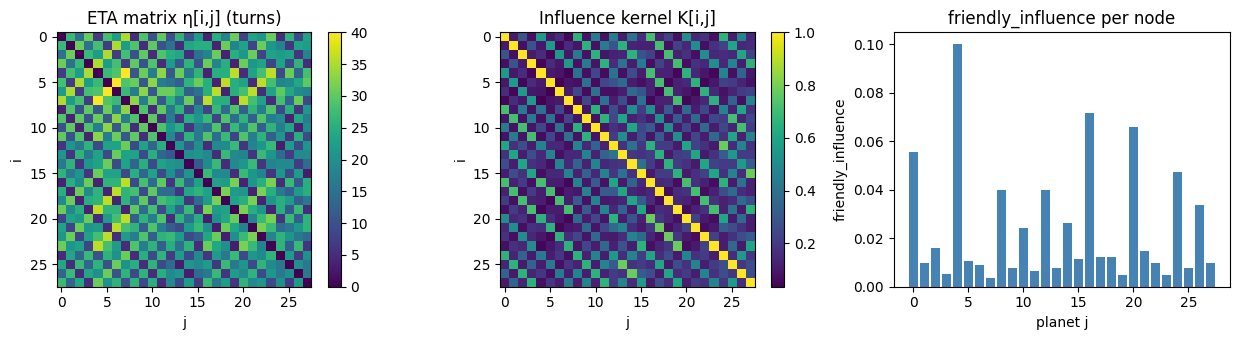


Per-metric summary (node j):
  [0] friendly_influence      min=+0.004  max=+0.100  mean=+0.024
  [1] enemy_influence         min=+0.004  max=+0.100  mean=+0.024
  [2] influence_balance       min=-0.096  max=+0.096  mean=+0.000
  [3] friendly_support        min=+0.000  max=+0.072  mean=+0.020
  [4] supportability          min=+0.000  max=+0.478  mean=+0.108
  [5] vulnerability           min=+0.003  max=+0.091  mean=+0.020
  [6] production_potential    min=+0.615  max=+0.876  mean=+0.768
  [7] strategic_potential     min=+0.518  max=+0.903  mean=+0.768


In [26]:
# Torch tensörleri (referans implementasyon ile aynı dtype/device)
feats_t = torch.from_numpy(obs.planet_feats).float().unsqueeze(0)   # (1, P, 34)
edge_t = torch.from_numpy(obs.edge_bias).float().unsqueeze(0)       # (1, P, P, 6)

with torch.no_grad():
    eta = _estimated_intercept_eta_matrix(feats_t[0], edge_t[0], n_real)  # (n, n)
    kernel = torch.exp(-eta / TAU)
    support_kernel = kernel.clone()
    support_kernel.fill_diagonal_(0.0)
    node_metrics_t = _graph_node_metrics(feats_t[0], edge_t[0], n_real, tau=TAU, eta=eta)

X_metrics = node_metrics_t.numpy().astype(np.float32)
print("eta shape       :", tuple(eta.shape), f"  max={eta.max():.2f} turns")
print("kernel shape    :", tuple(kernel.shape), f"  max={kernel.max():.3f}")
print("X_metrics shape :", X_metrics.shape)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, mat, title in zip(
    axes,
    [eta.numpy(), kernel.numpy(), None],
    ["ETA matrix η[i,j] (turns)", "Influence kernel K[i,j]", "friendly_influence per node"],
):
    if mat is None:
        ax.bar(range(n_real), X_metrics[:, 0], color="steelblue")
        ax.set_title(title)
        ax.set_xlabel("planet j"); ax.set_ylabel("friendly_influence")
    else:
        im = ax.imshow(mat, cmap="viridis")
        ax.set_title(title)
        ax.set_xlabel("j"); ax.set_ylabel("i")
        plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

print("\nPer-metric summary (node j):")
for k, name in enumerate(METRIC_NAMES):
    col = X_metrics[:, k]
    print(f"  [{k}] {name:22s}  min={col.min():+.3f}  max={col.max():+.3f}  mean={col.mean():+.3f}")

In [27]:
# Adım adım doğrulama: referans fonksiyon = elle aynı formüller
from model_graph_pyg import _owner_masks, PF_IDX_SHIPS, PF_IDX_PRODUCTION
from model_graph_pyg import PF_IDX_INCOMING_FRIENDLY_TOTAL, PF_IDX_INCOMING_ENEMY_TOTAL

with torch.no_grad():
    feats = feats_t[0, :n_real]
    is_self, is_enemy, _ = _owner_masks(feats)
    ships = feats[:, PF_IDX_SHIPS].clamp_min(0.0) * 100.0
    production = feats[:, PF_IDX_PRODUCTION].clamp_min(0.0) * 5.0
    incoming_friendly = feats[:, PF_IDX_INCOMING_FRIENDLY_TOTAL].clamp_min(0.0) * 100.0
    incoming_enemy = feats[:, PF_IDX_INCOMING_ENEMY_TOTAL].clamp_min(0.0) * 100.0
    friendly_sources = ships * is_self
    enemy_sources = ships * is_enemy

    raw_fi = kernel.T.matmul(friendly_sources)
    raw_ei = kernel.T.matmul(enemy_sources)
    raw_fs = support_kernel.T.matmul(friendly_sources)
    fi = raw_fi / 100.0
    ei = raw_ei / 100.0
    fs = raw_fs / 100.0
    sup = (raw_fs / (raw_ei + incoming_enemy + 1.0)).clamp(0.0, 10.0) / 10.0
    vul = (raw_ei / (ships + incoming_friendly + 1.0)).clamp(0.0, 10.0) / 10.0
    pp = kernel.T.matmul(production) / 25.0
    sp = pp + fi - ei
    manual = torch.stack([fi, ei, fi - ei, fs, sup, vul, pp, sp], dim=-1)

max_diff = (manual - node_metrics_t).abs().max().item()
print(f"manual vs _graph_node_metrics max |diff| = {max_diff:.2e}")
assert max_diff < 1e-5, "Metric mismatch — check formulas"

manual vs _graph_node_metrics max |diff| = 0.00e+00


## 4b. Flux, transit sırasında reward potansiyeli

Havadaki filo gezegende `ships` olarak yok → **base 8 metrik** influence'ı varışa kadar
hedefe taşımaz (kaynakta `ships↓`, hedefte sadece `incoming_*`).

**Flux (4 kanal)** filoyu `src → tgt` kenarı olarak yazar; ETA azaldıkça ağırlık artar:

    weight = ships · exp(−eta / τ_flux)

Aşağıda sentetik bir **capture launch** simüle edilir: kaynak gezegenden nötr hedefe
40 gemi, `eta = 25 → 0`. `φ(s)` = `graph_native` potansiyeli (flux açık).

In [ ]:
REWARD_CFG = build_reward_config("graph_native")
REWARD_CFG.enable_flux_metrics = True
REWARD_CFG.graph_flux_friendly_in_weight = 1.0
REWARD_CFG.graph_flux_friendly_out_weight = 1.0


def _ensure_fleet_arrays(obs, f_max=64):
    o = copy.deepcopy(obs)
    if o.fleet_mask.size == 0:
        o.fleet_mask = np.zeros(f_max, dtype=bool)
        o.fleet_src_slot = np.full(f_max, -1, dtype=np.int32)
        o.fleet_tgt_slot = np.full(f_max, -1, dtype=np.int32)
        o.fleet_eta_raw = np.zeros(f_max, dtype=np.float32)
        o.fleet_ships_raw = np.zeros(f_max, dtype=np.float32)
        o.fleet_is_self = np.zeros(f_max, dtype=bool)
        o.fleet_is_enemy = np.zeros(f_max, dtype=bool)
    return o


def _snapshot_potential(obs, cfg=REWARD_CFG):
    """φ(s) = ağırlıklı node_sum + edge_sum (anlık potansiyel)."""
    summary = compute_graph_metrics_summary(obs, cfg=cfg)
    weights = (
        cfg.graph_friendly_influence_weight,
        cfg.graph_enemy_influence_weight,
        cfg.graph_influence_balance_weight,
        cfg.graph_friendly_support_weight,
        cfg.graph_supportability_weight,
        cfg.graph_vulnerability_weight,
        cfg.graph_production_potential_weight,
        cfg.graph_strategic_potential_weight,
        cfg.graph_flux_friendly_in_weight,
        cfg.graph_flux_friendly_out_weight,
        cfg.graph_flux_enemy_in_weight,
        cfg.graph_flux_enemy_out_weight,
    )
    node = summary["node_sum"]
    w = weights[: len(node)]
    phi = sum(wi * ni for wi, ni in zip(w, node))
    phi += cfg.graph_edge_efficiency_weight * float(summary.get("edge_sum", 0.0))
    return phi, summary


def _simulate_launch_capture(obs, src, tgt, ships, eta, *, arrived=False):
    o = _ensure_fleet_arrays(obs)
    o.planet_feats = o.planet_feats.copy()
    o.planet_feats[src, PF_IDX_SHIPS] = max(
        0.0, o.planet_feats[src, PF_IDX_SHIPS] - ships / 100.0
    )
    if not arrived:
        o.planet_feats[tgt, PF_IDX_INCOMING_FRIENDLY_TOTAL] += ships / 100.0
        o.fleet_mask[0] = True
        o.fleet_src_slot[0] = src
        o.fleet_tgt_slot[0] = tgt
        o.fleet_ships_raw[0] = ships
        o.fleet_eta_raw[0] = float(eta)
        o.fleet_is_self[0] = True
        o.fleet_is_enemy[0] = False
    else:
        o.fleet_mask[:] = False
        o.planet_feats[tgt, PF_IDX_OWNER_SELF] = 1.0
        o.planet_feats[tgt, PF_IDX_OWNER_NEUTRAL] = 0.0
        o.planet_feats[tgt, PF_IDX_SHIPS] = ships / 100.0
        o.planet_feats[tgt, PF_IDX_INCOMING_FRIENDLY_TOTAL] = 0.0
    return o


src_slot = int(np.where(obs.source_mask[:n_real])[0][0])
neutral_slots = np.where(obs.planet_feats[:n_real, PF_IDX_OWNER_NEUTRAL] > 0.5)[0]
tgt_slot = int(neutral_slots[np.argmax(obs.planet_feats[neutral_slots, PF_IDX_PRODUCTION])])
ships_sent = 40.0
eta_launch = 25

baseline_obs = _ensure_fleet_arrays(obs)
phases = [("baseline", None, False)]
for eta in range(eta_launch, -1, -5):
    phases.append((f"transit η={eta}", float(eta), False))
phases.append(("arrival", 0.0, True))

rows = []
prev_phi = None
prev_summary = None
for name, eta, arrived in phases:
    if name == "baseline":
        snap = baseline_obs
    else:
        snap = _simulate_launch_capture(
            obs, src_slot, tgt_slot, ships_sent,
            eta if eta is not None else 0.0,
            arrived=arrived,
        )
    phi, summary = _snapshot_potential(snap)
    flux = compute_node_flux_features(snap, tau=FLUX_TAU)
    step_r = 0.0 if prev_summary is None else compute_graph_native_reward(
        prev_summary, summary, player=0, cfg=REWARD_CFG, turn=0,
    )
    rows.append({
        "phase": name,
        "phi": phi,
        "delta_phi": phi - prev_phi if prev_phi is not None else 0.0,
        "step_reward": step_r,
        "flux_in_tgt": flux[tgt_slot, 0],
        "flux_out_src": flux[src_slot, 1],
        "sum_friendly_inf": summary["node_sum"][0],
        "sum_prod_pot": summary["node_sum"][6],
    })
    prev_phi, prev_summary = phi, summary

print(f"Simülasyon: slot {src_slot} → slot {tgt_slot}, ships={ships_sent:.0f}, η_launch={eta_launch}")
print(f"{'phase':14s} {'φ(s)':>8s} {'Δφ':>8s} {'r_step':>8s} {'flux_in':>8s} {'Σfi':>8s} {'Σpp':>8s}")
for r in rows:
    print(
        f"{r['phase']:14s} {r['phi']:8.3f} {r['delta_phi']:8.3f} {r['step_reward']:8.4f} "
        f"{r['flux_in_tgt']:8.3f} {r['sum_friendly_inf']:8.3f} {r['sum_prod_pot']:8.3f}"
    )

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
transit = [r for r in rows if r["phase"].startswith("transit")]
x = [eta_launch - int(r["phase"].split("=")[1]) for r in transit]

axes[0].plot(x, [r["phi"] for r in transit], "o-", label="φ(s) total")
axes[0].set_xlabel("turns since launch"); axes[0].set_ylabel("φ(s)")
axes[0].set_title("Potansiyel transit boyunca (flux açık)")
axes[0].grid(alpha=0.3)

axes[1].plot(x, [r["flux_in_tgt"] for r in transit], "s-", color="C1", label="friendly_in[tgt]")
axes[1].plot(x, [r["flux_out_src"] for r in transit], "^--", color="C2", label="friendly_out[src]")
axes[1].set_xlabel("turns since launch"); axes[1].set_ylabel("flux (norm)")
axes[1].set_title("Flux kanalları ETA ile büyür")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)

labels = [r["phase"] for r in rows]
width = np.arange(len(rows))
axes[2].bar(width, [r["sum_friendly_inf"] for r in rows], alpha=0.7, label="Σ friendly_influence")
axes[2].bar(width, [r["sum_prod_pot"] for r in rows], alpha=0.5, label="Σ production_potential")
axes[2].set_xticks(width)
axes[2].set_xticklabels([l.replace("transit ", "t") for l in labels], rotation=45, ha="right", fontsize=7)
axes[2].set_title("Base-8 toplamları (varışta fi sıçrar, pp sabit)")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4c. Production artışı → topolojik metriklere etki

`production_potential` **sahiplikten bağımsız** hesaplanır:

    production_potential[j] = Σ_i K_ij · production_i / 25

Yani bir gezegendeki prod değişince **tüm haritaya** kernel ile yayılır.
**Capture** (ownership flip) prod hızını değiştirmezse `production_potential` **değişmez**;
asıl sıçrama `friendly_influence` ve `strategic_potential`'dadır.

Reward tasarımında bu ayrım kritik: capture'ı ödüllendirmek için `production_potential`
tek başına yeterli değil — **ownership-masked** veya **friendly_influence** kanalı gerekir.

In [ ]:
feats_t = torch.from_numpy(obs.planet_feats).float()
edge_t = torch.from_numpy(obs.edge_bias).float()
neutral_slots = np.where(obs.planet_feats[:n_real, PF_IDX_OWNER_NEUTRAL] > 0.5)[0]
with torch.no_grad():
    eta_mat = _estimated_intercept_eta_matrix(feats_t, edge_t, n_real)
    metrics_base = _graph_node_metrics(feats_t, edge_t, n_real, eta=eta_mat).numpy()

# --- Deney A: owned gezegende prod +5 (normalize +1.0) ---
owned_slots = np.where(obs.planet_feats[:n_real, PF_IDX_OWNER_SELF] > 0.5)[0]
obs_prod_up = copy.deepcopy(obs)
obs_prod_up.planet_feats = obs_prod_up.planet_feats.copy()
if len(owned_slots):
    p = int(owned_slots[0])
    obs_prod_up.planet_feats[p, PF_IDX_PRODUCTION] += 1.0
    with torch.no_grad():
        m_up = _graph_node_metrics(
            torch.from_numpy(obs_prod_up.planet_feats).float(),
            edge_t, n_real, eta=eta_mat,
        ).numpy()
    delta_prod = m_up - metrics_base
else:
    p, delta_prod = None, np.zeros_like(metrics_base)

# --- Deney B: sadece ownership flip (capture), prod aynı ---
obs_cap = copy.deepcopy(obs)
obs_cap.planet_feats = obs_cap.planet_feats.copy()
cap_tgt = int(neutral_slots[0]) if len(neutral_slots) else 0
obs_cap.planet_feats[cap_tgt, PF_IDX_OWNER_SELF] = 1.0
obs_cap.planet_feats[cap_tgt, PF_IDX_OWNER_NEUTRAL] = 0.0
with torch.no_grad():
    m_cap = _graph_node_metrics(
        torch.from_numpy(obs_cap.planet_feats).float(),
        edge_t, n_real, eta=eta_mat,
    ).numpy()
delta_cap = m_cap - metrics_base

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
if p is not None:
    im0 = axes[0].imshow(delta_prod[:, 6][:, None] * np.ones(n_real), aspect="auto", cmap="YlOrRd")
    axes[0].set_title(f"Δ production_potential\n(owned slot {p}: prod +5)")
    axes[0].set_xlabel("dummy"); axes[0].set_ylabel("planet j")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)
else:
    axes[0].text(0.5, 0.5, "owned planet yok", ha="center", transform=axes[0].transAxes)

im1 = axes[1].imshow(delta_cap[:, 0][:, None] * np.ones(n_real), aspect="auto", cmap="RdBu_r")
axes[1].set_title(f"Δ friendly_influence\n(capture slot {cap_tgt}, prod sabit)")
axes[1].set_xlabel("dummy"); axes[1].set_ylabel("planet j")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

for label, delta in [("prod +5 at owned", delta_prod), ("capture only", delta_cap)]:
    print(f"\n{label}:")
    for k, name in enumerate(METRIC_NAMES):
        print(f"  {name:22s}  ΣΔ={delta[:, k].sum():+.4f}  max|Δ|={np.abs(delta[:, k]).max():.4f}")

## 4d. Oyun-sonu gezegen bazlı credit dağıtımı — tasarım tartışması

**Fikir:** Episode bitince her gezegen j için kanal bazlı net kazanç kaydet:

    ΔM_j,c = M_j,c(s_final) − M_j,c(s_initial)

Sonra bu Δ'ları, o gezegenden yapılan veya o gezegene yapılan launch'lara dağıt.

### Neden cazip?

| Artı | Eksi |
|------|------|
| Lokal attribution (hangi gezegen kazandı/kaybetti) | Sparse reward — gradient gecikmesi |
| Launch–target çiftine doğrudan credit | Düşman hamleleri de ΔM'yi değiştirir |
| Capture'da tgt slot net kazanç görür | Birden fazla launch aynı Δ'yı paylaşır |

### Önerilen hibrit (3 katman)

```text
Katman 1 — Online potential (mevcut)
  r_t = γ φ(s_{t+1}) − φ(s_t)     flux açık → transit credit

Katman 2 — Arrival credit (mevcut, Option B)
  launch adımına: w(η) · ⟨w, M_tgt(s_arrive) − M_tgt(s_launch)⟩

Katman 3 — Episode reconcile (yeni, opsiyonel)
  episode sonu: ΔM_j,c^net = M_j,c(T) − M_j,c(0)
  launch k seti L_j = { launches with src=j or tgt=j }
  credit_i ∝ eligibility_i · Σ_{c} w_c · ΔM_j,c^net / |L_j|
```

Katman 3 **Katman 1–2'yi değiştirmez**, residual olarak eklenebilir — ama
double-counting riski yüksek; ya online reward'ı düşür ya da sadece
**terminal olmayan oyunlarda** (win/loss) kullan.

### Production için ownership-mask şart

Global `Σ_j production_potential` capture'ı ödüllendirmez (nötr zaten prod
veriyordu). Episode credit da aynı tuzağa düşer. Öneri:

```text
ΔM_j,c  sadece is_self(j) gezegenlerde savunma kanalları için
ΔM_j,c  enemy/neutral(j) için saldırı kanalları + capture_value
production_potential  →  sadece yeni prod kazanımı:
    Δ prod_j · remaining_turns  (capture_value ile hizalı)
```

### Dağıtım kuralı örneği

Bir launch `(src, tgt, ships, η)` için episode sonu payı:

```text
credit_launch = α · Σ_c w_c · [ ΔM_tgt,c^net · w_tgt + ΔM_src,c^net · w_src ]
```

`w_tgt > w_src` (hedef etkisi daha ağır). Aynı tgt'ye N launch varsa
`1/N` veya ETA-kernel ile paylaştır.

### Pratik öneri

1. **Şimdi:** `graph_native` + flux + arrival_credit — online, teorik garantili
2. **Sonra:** Episode reconcile'ı yalnızca **eval / logging** için dene;
   policy gradient'e eklemeden launch attribution kalitesini ölç
3. **Production reward:** `capture_value` veya ownership-masked
   `friendly_influence` kullan; ham `production_potential` delta'sını
   capture ödülü sanma

Mevcut kod: `rl/rewards.py` (potential), `rl/arrival_credit.py` (launch→tgt),
`rl/flux.py` (transit). Episode-level dağıtım henüz yok — Katman 3 yeni modül olur.

## 5. GNN node girdisi: concat `(n, 42)`

```python
X_gnn = concat([planet_feats, graph_node_metrics], axis=-1)  # (n, 34+8)
```

Ayrı bir `NodeEmbed` katmanı **yok** — bu vektör doğrudan GINEConv'a girer.

X_gnn shape: (28, 42)
  cols 0-33     : ham planet_feats
  cols 34-41 : graph node metrics


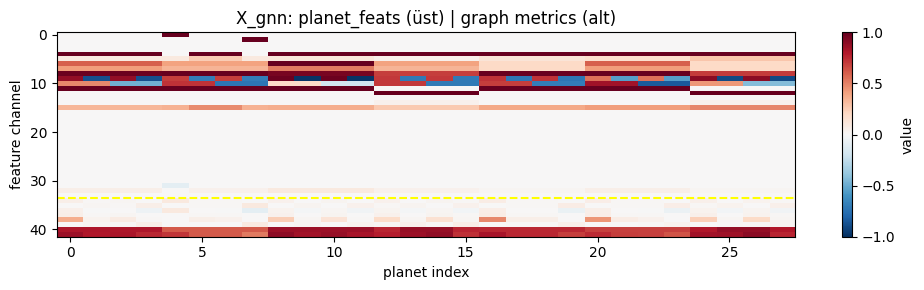

In [28]:
X_gnn = np.concatenate([X_planet, X_metrics], axis=-1).astype(np.float32)
print("X_gnn shape:", X_gnn.shape)
print(f"  cols 0-{PLANET_FEATURE_DIM-1}     : ham planet_feats")
print(f"  cols {PLANET_FEATURE_DIM}-{GNN_NODE_DIM-1} : graph node metrics")

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(X_gnn.T, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.axhline(PLANET_FEATURE_DIM - 0.5, color="yellow", lw=1.5, ls="--")
ax.set_title("X_gnn: planet_feats (üst) | graph metrics (alt)")
ax.set_xlabel("planet index"); ax.set_ylabel("feature channel")
plt.colorbar(im, ax=ax, label="value")
plt.tight_layout()
plt.show()

## 6. Edge feature = mesafe `(n, n)`

Kenar `(i → j)` için tek skaler: **normalize Euclidean mesafe**.

`edge_bias[i, j, 0] = dist(i, j) / 100`

D shape: (28, 28)   min=0.0000 max=1.2477


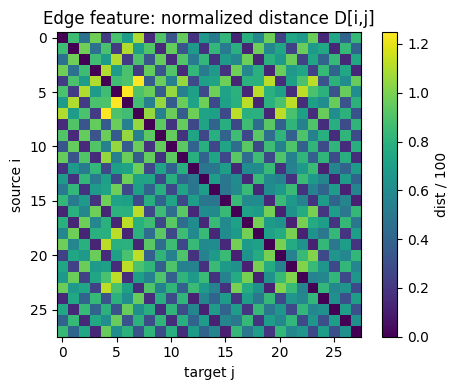

In [29]:
P = obs.planet_feats.shape[0]
D = obs.edge_bias[:P, :P, EB_DIST][:n_real, :n_real].astype(np.float32)

print("D shape:", D.shape, f"  min={D.min():.4f} max={D.max():.4f}")

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(D, cmap="viridis")
ax.set_title("Edge feature: normalized distance D[i,j]")
ax.set_xlabel("target j"); ax.set_ylabel("source i")
plt.colorbar(im, ax=ax, label="dist / 100")
plt.tight_layout()
plt.show()

## 7. Fully connected directed graph

- `edge_index`: `(2, n·(n-1))` — tüm ordered pair, self-loop yok
- `edge_attr`: `(E, 1)` — her kenar için `D[src, dst]`

In [30]:
edge_index = _planet_edge_index(n_real)
E = edge_index.shape[1]
print(f"edge_index {tuple(edge_index.shape)}  E = {E} = {n_real}*({n_real}-1)")

src = edge_index[0].numpy()
dst = edge_index[1].numpy()
edge_attr = D[src, dst][:, None]
print("edge_attr shape:", edge_attr.shape)
print("first 5 distances:", edge_attr[:5].ravel())

edge_index (2, 756)  E = 756 = 28*(28-1)
edge_attr shape: (756, 1)
first 5 distances: [0.85885316 0.46783993 0.97800964 0.21678105 0.8876835 ]


## 8. NodeEmbed / EdgeEmbed — **kullanılmıyor** (referans prototip)

Erken taslakta GNN öncesi ayrı projeksiyon düşünülmüştü. **Yeni karar:** embed katmanı yok;
ham + metrik feature doğrudan GNN'e gider. Kod referans için notebook'ta kalıyor.

In [31]:
class NodeEmbed(nn.Module):
    """DEPRECATED — yeni tasarımda kullanılmaz."""
    def __init__(self, in_dim=GNN_NODE_DIM, d_model=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Linear(in_dim, d_model),
            nn.GELU(),
            nn.LayerNorm(d_model),
        )

    def forward(self, x):
        return self.net(x)


class EdgeEmbed(nn.Module):
    """DEPRECATED — yeni tasarımda kullanılmaz."""
    def __init__(self, d_model=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(1),
            nn.Linear(1, d_model),
            nn.GELU(),
            nn.LayerNorm(d_model),
        )

    def forward(self, e):
        return self.net(e)

print("NodeEmbed / EdgeEmbed tanımlı ama pipeline'da çağrılmıyor.")

NodeEmbed / EdgeEmbed tanımlı ama pipeline'da çağrılmıyor.


## 9. PyG `Data` paketi

In [32]:
from torch_geometric.data import Data

data = Data(
    x=torch.from_numpy(X_gnn),
    edge_index=edge_index,
    edge_attr=torch.from_numpy(edge_attr),
    num_nodes=n_real,
)
print("PyG Data OK")
print(f"  x          {tuple(data.x.shape)}   ← 34 planet + 8 metrics")
print(f"  edge_index {tuple(data.edge_index.shape)}")
print(f"  edge_attr  {tuple(data.edge_attr.shape)}   ← mesafe only")

PyG Data OK
  x          (28, 42)   ← 34 planet + 8 metrics
  edge_index (2, 756)
  edge_attr  (756, 1)   ← mesafe only


## 10. Doğrudan FC GNN (GINEConv) — embed yok

Prototip: `in_channels=42`, `edge_dim=1`. İlk katman ham feature'ı alır;
mesafe kenar attribute olarak message passing'e girer.

In [33]:
from torch_geometric.nn import GINEConv


def _make_gine(in_dim, out_dim, edge_dim):
    return GINEConv(
        nn.Sequential(
            nn.Linear(in_dim, out_dim),
            nn.GELU(),
            nn.Linear(out_dim, out_dim),
        ),
        edge_dim=edge_dim,
    )


class DirectFcPlanetGnn(nn.Module):
    """Ham node (42) + mesafe edge (1) → GINE stack. Embed yok."""

    def __init__(self, in_dim=GNN_NODE_DIM, edge_dim=GNN_EDGE_DIM, hidden=HIDDEN, num_layers=2):
        super().__init__()
        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()
        d_in = in_dim
        for _ in range(num_layers):
            self.convs.append(_make_gine(d_in, hidden, edge_dim))
            self.norms.append(nn.LayerNorm(hidden))
            d_in = hidden
        self.out_dim = hidden

    def forward(self, x, edge_index, edge_attr):
        for conv, norm in zip(self.convs, self.norms):
            x = conv(x, edge_index, edge_attr)
            x = norm(x)
            x = torch.nn.functional.gelu(x)
        return x


gnn = DirectFcPlanetGnn()
gnn.eval()
with torch.no_grad():
    H = gnn(data.x, data.edge_index, data.edge_attr)

print("GNN output H shape:", tuple(H.shape))
print("  input  : X_gnn (n, 42) — no NodeEmbed")
print("  edges  : distance (E, 1) — no EdgeEmbed")

GNN output H shape: (28, 96)
  input  : X_gnn (n, 42) — no NodeEmbed
  edges  : distance (E, 1) — no EdgeEmbed


## 11. Mevcut `PygPlanetGraphEncoder` ile fark

| | Mevcut encoder | Yeni tasarım |
|--|----------------|--------------|
| Node input | 42 (34+8 metric) | **42 (34+8 metric)** — aynı boyut |
| Edge input | 15 (geom + graph metric) | **1 (mesafe only)** |
| Ön projeksiyon | `node_proj` + `edge_proj` → d_model | **yok** — doğrudan GNN |
| Topoloji | FC directed | FC directed (aynı) |
| Sonrası | policy head | **TODO** policy head |

## 12. Kontrol listesi

- [x] Node = 34 `planet_feats` + 8 graph metric concat
- [x] Graph metrik hesabı notebook'ta gösterildi
- [x] Embed katmanı kullanılmıyor
- [ ] Edge'e sadece mesafe yeterli mi? (crosses_sun, Δφ eklensin mi?)
- [ ] Flux metrikleri (4 kanal) node'a eklensin mi? → opsiyonel Phase 2
- [ ] Fleet/global ileride graph'a girmeli mi?

**Sonraki adım (onayından sonra):** policy head `(src, tgt, ship)` + eğitim loop.